# Assignment 6 â€“ Handwritten Letter Recognition with Ensemble Models

**Goal:** predict the handwritten letters **A, B and C**.

- Training images: `train images/A`, `B`, `C`
- Testing images: `test images/` (mixed; the first character of each filename is the true letter)

Models compared: **Random Forest, AdaBoost, Gradient Boosting**.

In [31]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix

# dim = image resolution the model sees (dim x dim pixels).
# Higher = more detail, but more features and slower training.
dim = 64
TRAIN_DIR = "train images"
TEST_DIR = "test images"

## Load the images
Each image is converted to grayscale, resized to `dim x dim`, scaled to 0â€“1 and flattened into one row of pixels. Pixels are inverted so the ink is the high value.

In [32]:
def load_image(path):
    img = Image.open(path).convert("L").resize((dim, dim))
    return 1 - np.asarray(img, dtype=float).flatten() / 255.0

def is_image(f):
    return f.lower().endswith((".png", ".jpg", ".jpeg"))

train_files, y_train = [], []
for letter in sorted(os.listdir(TRAIN_DIR)):
    folder = os.path.join(TRAIN_DIR, letter)
    if os.path.isdir(folder):
        for f in sorted(os.listdir(folder)):
            if is_image(f):
                train_files.append(os.path.join(folder, f))
                y_train.append(letter)

test_files = sorted(os.path.join(TEST_DIR, f) for f in os.listdir(TEST_DIR) if is_image(f))
y_test = np.array([os.path.basename(f)[0].upper() for f in test_files])

X_train = np.array([load_image(f) for f in train_files])
y_train = np.array(y_train)
X_test = np.array([load_image(f) for f in test_files])
print("Train:", X_train.shape, dict(zip(*np.unique(y_train, return_counts=True))))
print("Test: ", X_test.shape, dict(zip(*np.unique(y_test, return_counts=True))))

Train: (33, 4096) {'A': 10, 'B': 15, 'C': 8}
Test:  (6, 4096) {'A': 2, 'B': 2, 'C': 2}


## Show the training and testing data

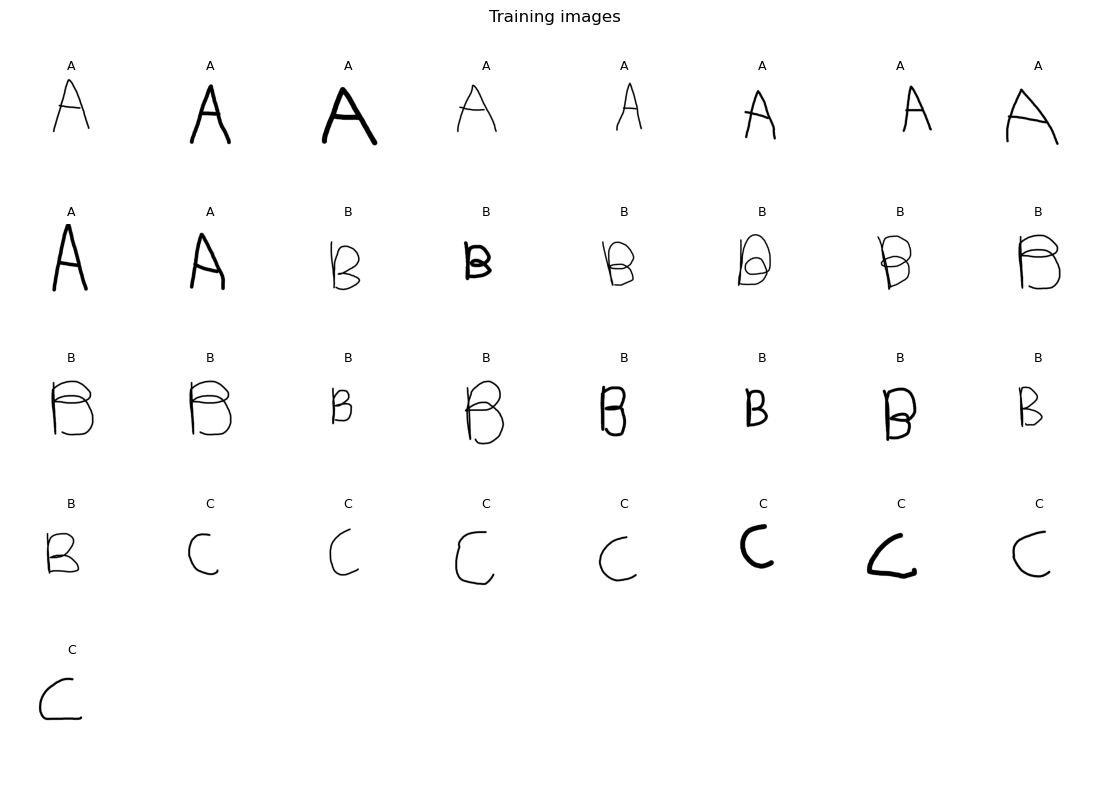

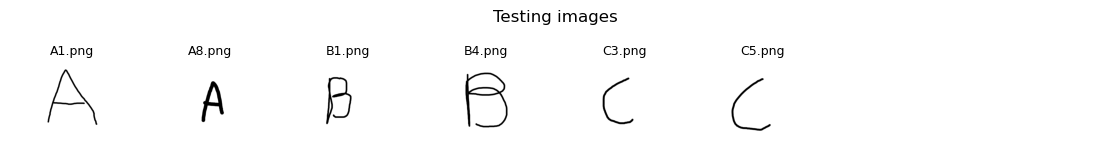

In [33]:
def show(files, labels, title, ncol=8):
    nrow = int(np.ceil(len(files) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 1.4, nrow * 1.6))
    for ax in np.array(axes).flatten():
        ax.axis("off")
    for ax, f, lab in zip(np.array(axes).flatten(), files, labels):
        ax.imshow(Image.open(f).convert("L"), cmap="gray")
        ax.set_title(lab, fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show(train_files, y_train, "Training images")
show(test_files, [os.path.basename(f) for f in test_files], "Testing images")

## Tuning parameters

| Model | Parameter | What it does |
|:-|:-|:-|
| Random Forest | `n_estimators` | Number of trees. More trees = more stable votes, slower. |
| | `max_depth` | How deep each tree grows. `None` = until pure; smaller limits overfitting. |
| | `max_features` | Pixels considered at each split. `sqrt` adds randomness so trees differ. |
| AdaBoost | `n_estimators` | Number of weak learners added one after another. |
| | `learning_rate` | How much each new learner counts. Smaller = slower, often more accurate with more estimators. |
| | `estimator__max_depth` | Depth of each weak tree (1 = stump). |
| Gradient Boosting | `n_estimators` | Number of boosting rounds. |
| | `learning_rate` | Shrinks each tree's contribution; trades off with `n_estimators`. |
| | `max_depth` | Depth of each tree. |
| All | `dim` (top of notebook) | Image resolution: more pixels = model sees letters more clearly. |

Each grid below is searched with 3-fold cross-validation on the training data only; the test images are never used for tuning.

In [35]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

models = {
    "Random Forest": (RandomForestClassifier(random_state=42), {
        "n_estimators": [100, 300, 500, 1000],
        "max_depth": [None, 10, 5],
        "max_features": ["sqrt", "log2"],
    }),
    "AdaBoost": (AdaBoostClassifier(estimator=DecisionTreeClassifier(), random_state=42), {
        "n_estimators": [50, 200],
        "learning_rate": [0.1, 0.5, 1.0],
        "estimator__max_depth": [1, 2, 3],
    }),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42), {
        "n_estimators": [50, 150],
        "learning_rate": [0.05, 0.1, 0.3],
        "max_depth": [1, 2, 3],
    }),
}

best = {}
for name, (model, grid) in models.items():
    search = GridSearchCV(model, grid, cv=cv, scoring="accuracy", n_jobs=-1)
    search.fit(X_train, y_train)
    best[name] = search.best_estimator_
    print(f"{name}: CV accuracy {search.best_score_:.3f} with {search.best_params_}")

Random Forest: CV accuracy 0.818 with {'max_depth': None, 'max_features': 'log2', 'n_estimators': 100}


c:\Users\student\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


AdaBoost: CV accuracy 0.727 with {'estimator__max_depth': 1, 'learning_rate': 0.5, 'n_estimators': 50}
Gradient Boosting: CV accuracy 0.727 with {'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 150}


## Test the models

In [36]:
results = {}
for name, model in best.items():
    pred = model.predict(X_test)
    results[name] = pred
    print()
    print(f"{name}: test accuracy {accuracy_score(y_test, pred):.3f}")
    print(confusion_matrix(y_test, pred, labels=model.classes_))

print()
print("Per image:")
for i, f in enumerate(test_files):
    row = "  ".join(f"{n[:2]}={results[n][i]}" for n in results)
    flag = "" if all(results[n][i] == y_test[i] for n in results) else "  <-- wrong"
    print(f"{os.path.basename(f):10s} true={y_test[i]}  {row}{flag}")


Random Forest: test accuracy 0.833
[[1 1 0]
 [0 2 0]
 [0 0 2]]

AdaBoost: test accuracy 1.000
[[2 0 0]
 [0 2 0]
 [0 0 2]]

Gradient Boosting: test accuracy 0.833
[[1 0 1]
 [0 2 0]
 [0 0 2]]

Per image:
A1.png     true=A  Ra=B  Ad=A  Gr=A  <-- wrong
A8.png     true=A  Ra=A  Ad=A  Gr=C  <-- wrong
B1.png     true=B  Ra=B  Ad=B  Gr=B
B4.png     true=B  Ra=B  Ad=B  Gr=B
C3.png     true=C  Ra=C  Ad=C  Gr=C
C5.png     true=C  Ra=C  Ad=C  Gr=C
